# Entrega 3 · Modelado — F1 Strategy Pipeline
**Ciencia de Datos · UTN FRM · 2026**  
**Versión corregida y reproducible para los dos Silver adjuntos**

**Problema:** sistema supervisado de dos decisiones: (1) `pit_stop`: ¿parar durante la próxima vuelta?; (2) `new_compound`: si se decide parar, ¿qué compuesto recomendar? Ambas etapas se entrenan y miden por separado, y luego se evalúan conjuntamente.  
**Criterio de evaluación:** las elecciones se hacen solamente con 2023–2024. Se reserva 2025 para la evaluación final. Las métricas del test **no se utilizan para retocar** modelos, variables ni umbrales. Se documenta que las versiones anteriores ya inspeccionaron 2025, por lo que ese conjunto **no es un test completamente virgen a nivel del proyecto**.

> Esta versión reestructura el código de la entrega anterior para usar **una misma ingeniería de variables históricas en ambas etapas**. En consecuencia, los números anteriores (por ejemplo, F1 macro 0,651 del modelo antiguo de compuesto) **no deben copiarse como resultados del sistema nuevo**. Las lecturas cuantitativas se generan a partir de la ejecución actual.

## 0 · Preparación y reproducibilidad
- Semilla `42` para separaciones, modelos y permutaciones.
- Subir los dos archivos Silver al panel **Archivos** de Colab, con sus nombres originales (acepta sufijos como `(1)` o `(2)`).
- No es necesario subir un notebook adicional. Si se usa Drive, cambiar `DIR_DATOS` por la ruta correspondiente.
- Los artefactos finales se guardan en `/content` o en el directorio de ejecución.

In [33]:
# ============================================================
# 0. CONFIGURACIÓN, REPRODUCIBILIDAD Y CARGA DE DATOS
# ============================================================

import os
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    precision_recall_curve
)

from sklearn.model_selection import (
    StratifiedGroupKFold,
    GroupKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

import joblib


# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

SEED = 42
np.random.seed(SEED)

ORDEN = ['SOFT', 'MEDIUM', 'HARD', 'LLUVIA']

CLAVE = ['session_key', 'driver_number', 'lap_number']

pd.set_option('display.max_columns', 30)

warnings.filterwarnings('ignore', category=FutureWarning)


# ============================================================
# 2. UBICACIÓN DE LOS ARCHIVOS
# ============================================================

DIR_DATOS = (
    Path('/content')
    if Path('/content').is_dir()
    else Path.cwd()
)

# Dimensiones esperadas de los Silver de las Entregas 1 y 2.
FILAS_ESPERADAS = {
    'f1_silver_dataset': 77373,
    'f1_silver_pit_stops': 2333
}

COLUMNAS_ESPERADAS = {
    'f1_silver_dataset': 89,
    'f1_silver_pit_stops': 93
}


# ============================================================
# 3. BUSCAR Y VALIDAR ARCHIVOS SILVER
# ============================================================

def buscar_csv(stem):

    directorios = [
        DIR_DATOS,
        Path('/mnt/data'),
        Path('include/output/silver'),
        Path('../include/output/silver')
    ]

    candidatos = []

    for directorio in directorios:

        if directorio.exists():

            candidatos.extend(
                directorio.glob(stem + '*.csv')
            )

    # Eliminar rutas repetidas.
    candidatos = sorted(set(candidatos))

    if not candidatos:

        raise FileNotFoundError(
            f'No encontré archivos para {stem}. '
            'Subí los dos CSV Silver a Google Colab.'
        )

    print(f'\nBuscando: {stem}')

    archivos_validos = []

    for archivo in candidatos:

        try:

            tabla = pd.read_csv(
                archivo,
                low_memory=False
            )

            filas, columnas = tabla.shape

            print(
                f'  {archivo.name}: '
                f'{filas} filas, {columnas} columnas'
            )

            # Validar dimensiones esperadas.
            if (
                filas == FILAS_ESPERADAS[stem]
                and columnas == COLUMNAS_ESPERADAS[stem]
            ):

                archivos_validos.append(
                    (archivo, tabla)
                )

        except Exception as e:

            print(
                f'  Error leyendo {archivo.name}: {e}'
            )

    if not archivos_validos:

        raise ValueError(
            f'No encontré una versión válida de {stem}. '
            f'Se esperaban {FILAS_ESPERADAS[stem]} filas '
            f'y {COLUMNAS_ESPERADAS[stem]} columnas. '
            'Verificá que hayas subido los Silver correctos.'
        )

    # Priorizar la versión válida más recientemente modificada.
    elegido, tabla = max(
        archivos_validos,
        key=lambda item: item[0].stat().st_mtime
    )

    print(f'ARCHIVO SELECCIONADO: {elegido.name}')

    return elegido, tabla


# ============================================================
# 4. CARGAR LOS DOS DATASETS
# ============================================================

f_vueltas, raw = buscar_csv(
    'f1_silver_dataset'
)

f_pits, raw_pits = buscar_csv(
    'f1_silver_pit_stops'
)


# ============================================================
# 5. VALIDACIONES DE INTEGRIDAD
# ============================================================

print('\n========== VALIDACIÓN DE SILVER ==========')

print('Vueltas:', raw.shape)
print('Paradas:', raw_pits.shape)

# Verificar las columnas que identifican cada observación.
assert set(CLAVE).issubset(raw.columns), (
    'Faltan columnas clave en el dataset de vueltas.'
)

assert set(CLAVE).issubset(raw_pits.columns), (
    'Faltan columnas clave en el dataset de paradas.'
)

# No deben existir filas duplicadas por carrera, piloto y vuelta.
assert raw.duplicated(CLAVE).sum() == 0, (
    'Existen vueltas duplicadas.'
)

assert raw_pits.duplicated(CLAVE).sum() == 0, (
    'Existen paradas duplicadas.'
)

# Las carreras del CSV de paradas deben existir en el de vueltas.
carreras_vueltas = set(raw['session_key'].dropna())

carreras_paradas = set(raw_pits['session_key'].dropna())

assert carreras_paradas.issubset(carreras_vueltas), (
    'Hay carreras en el CSV de paradas que no aparecen '
    'en el CSV de vueltas.'
)

print('\nValidaciones de integridad superadas.')

print('\nCarreras en vueltas:', raw.session_key.nunique())

print('Carreras en paradas:', raw_pits.session_key.nunique())


# ============================================================
# 6. RESUMEN POR TEMPORADA
# ============================================================

print('\n========== VUELTAS POR TEMPORADA ==========')

display(
    raw.groupby('season').agg(
        vueltas=('lap_number', 'size'),
        carreras=('session_key', 'nunique')
    )
)

print('\n========== PARADAS POR TEMPORADA ==========')

display(
    raw_pits.groupby('season').agg(
        paradas=('lap_number', 'size'),
        carreras=('session_key', 'nunique')
    )
)

print('\n✅ PASO 0 COMPLETADO CORRECTAMENTE')


Buscando: f1_silver_dataset
  f1_silver_dataset.csv: 77373 filas, 89 columnas
ARCHIVO SELECCIONADO: f1_silver_dataset.csv

Buscando: f1_silver_pit_stops
  f1_silver_pit_stops.csv: 2333 filas, 93 columnas
ARCHIVO SELECCIONADO: f1_silver_pit_stops.csv

========== VALIDACIÓN DE SILVER ==========
Vueltas: (77373, 89)
Paradas: (2333, 93)

Validaciones de integridad superadas.

Carreras en vueltas: 70
Carreras en paradas: 64

========== VUELTAS POR TEMPORADA ==========


,vueltas,carreras
season,,
2023,24479,22
2024,26629,24
2025,26265,24



========== PARADAS POR TEMPORADA ==========


,paradas,carreras
season,,
2023,693,16
2024,825,24
2025,815,24



✅ PASO 0 COMPLETADO CORRECTAMENTE


## 1 · Correcciones de la Entrega 2 y definición de información disponible
Se elimina del modelado la información posterior a la decisión: `new_compound`, duraciones de la parada, datos del stint nuevo, duración de la vuelta actual, resultado de la vuelta actual, banderas descartadas y máximos finales observados. Las variables de estado se construyen exclusivamente con **vueltas anteriores del mismo piloto** (`shift(1)`). El estado de neumáticos del pelotón usa la vuelta anterior de cada carrera, no su resultado posterior.

**Sobre las observaciones del docente:** se excluyen `safety_car_active`, `yellow_flag_*`, `i1_speed`, `st_speed` e `interval*`; se eliminan filas sin etiqueta `pit_stop`. Para no arrastrar el problema de `gap_to_leader_raw` (texto `+N LAP` y máximos dependientes del conjunto) se **omite por completo del modelo final**: evita una codificación artificial que no mejoró el modelo en el experimento anterior. Si el equipo necesita incluirlo, deberá transformarlo con estadísticas aprendidas sólo en el entrenamiento de cada fold.

**Decisión sobre `scheduled_laps`:** no se usa el máximo observado de las tres temporadas para inferir vueltas programadas, ya que puede revelar datos del futuro. Usamos `lap_number` como momento de carrera, que sí es conocido al comenzar la vuelta. Esta exclusión es una corrección metodológica respecto del notebook anterior.

In [34]:
# Conservar solo carreras con objetivo observable; NO imputar pit_stop nulo como False.
vueltas = raw.loc[raw['pit_stop'].notna()].copy()
vueltas['pit_stop'] = vueltas['pit_stop'].astype(str).str.lower().eq('true') | (vueltas['pit_stop'] == 1)
vueltas['season'] = pd.to_numeric(vueltas['season'], errors='raise').astype(int)
vueltas = vueltas.sort_values(CLAVE).reset_index(drop=True)

# Corrección acotada de inconsistencia de origen: Bélgica 2025, stint 2 sin parada previa.
# El detector usa SOLO historia de neumáticos y paradas, nunca el compuesto que se intenta predecir.
stints = (vueltas.groupby(['session_key','driver_number','stint_number'], dropna=False)
          .agg(primera=('lap_number','min'),ultima=('lap_number','max'),compuesto=('current_compound','first')).reset_index())
s1 = stints[(stints.stint_number == 1)&(stints.ultima == 1)]
s2 = stints[(stints.stint_number == 2)&(stints.primera == 2)]
candidatos = s1.merge(s2, on=['session_key','driver_number'],suffixes=('_1','_2'))
paradas_1_2 = (vueltas.loc[vueltas.pit_stop & vueltas.lap_number.le(2)]
               .groupby(['session_key','driver_number']).size())
candidatos['parada_temprana'] = candidatos.set_index(['session_key','driver_number']).index.map(paradas_1_2).fillna(0)
corregir = candidatos.loc[candidatos.compuesto_1.ne(candidatos.compuesto_2) & candidatos.parada_temprana.eq(0),
                          ['session_key','driver_number','compuesto_1']].copy()
if len(corregir):
    clave_corr = corregir.set_index(['session_key','driver_number'])['compuesto_1']
    idx = pd.MultiIndex.from_frame(vueltas[['session_key','driver_number']])
    previo = pd.Series(idx.map(clave_corr), index=vueltas.index)
    mask = previo.notna() & vueltas.stint_number.eq(2)
    vueltas.loc[mask,'current_compound'] = previo[mask]
    # No se reajusta tyre_age sin evidencia del registro exacto de edad.
print('Pilotos con inconsistencia de stint detectada:',len(corregir))
print('Vueltas sin etiqueta descartadas:',raw.pit_stop.isna().sum())
print('Vueltas válidas:',len(vueltas),'| Paradas reales:',int(vueltas.pit_stop.sum()))
assert set(vueltas.season.unique()) >= {2023,2024,2025}

Pilotos con inconsistencia de stint detectada: 20
Vueltas sin etiqueta descartadas: 6627
Vueltas válidas: 70746 | Paradas reales: 2333


## 1.1. Seguimiento de las observaciones de la Entrega 2

En la Entrega 2 realizamos el análisis exploratorio de los datos
obtenidos mediante el pipeline de Airflow.

A partir de la devolución del docente, incorporamos correcciones
sobre la preparación de datos y la interpretación de las hipótesis.

Estas modificaciones buscan mejorar la calidad de los datos y
evitar utilizar información que no estaría disponible al momento
de realizar una recomendación estratégica.

| N.º | Observación del docente | Corrección aplicada |
|---|---|---|
| 1 | Convertir `gap_to_leader` a segundos enteros | Se implementó una transformación descriptiva que convierte los valores numéricos a segundos enteros y reemplaza las referencias a vueltas de diferencia por el máximo observado. |
| 2 | Asignar distancia cero al líder | Se establece `gap_to_leader = 0` cuando `position = 1`. |
| 3 | Eliminar la columna de safety car | Se excluye `safety_car_active` de las variables utilizadas para entrenar los modelos. |
| 4 | Eliminar las banderas amarillas | Se excluyen `yellow_flag_active` y `yellow_flag_scope`. |
| 5 | Eliminar `i1_speed` | La variable no participa en el modelado. |
| 6 | Eliminar `st_speed` | La variable no participa en el modelado. |
| 7 | Eliminar `interval` | Se excluyen `interval` e `interval_raw`. |
| 8 | Eliminar filas con `pit_stop` nulo | Se descartan las observaciones sin etiqueta válida, evitando interpretarlas incorrectamente como vueltas sin parada. |
| 9 | Reemplazar el gráfico de la hipótesis 1 | Se incorpora un histograma normalizado de la edad del neumático antes de la vuelta, diferenciando las vueltas con y sin parada. |
| 10 | Revisar la hipótesis 4 | Se analiza la relación entre safety car y los neumáticos INTERMEDIATE/WET para distinguir el efecto de la lluvia. |

**Consideración metodológica sobre `gap_to_leader`:**

Aunque recuperamos la transformación solicitada por el docente,
decidimos no incluir esta variable en los modelos finales de
la Entrega 3.

Esta decisión evita utilizar un máximo calculado sobre carreras
futuras y mantiene la comparación de modelos realizada mediante
validación cruzada.

La transformación se conserva como corrección descriptiva del
análisis de la Entrega 2, sin modificar los datos utilizados
durante el entrenamiento.

Las demás variables descartadas permanecen disponibles en
los archivos Silver originales cuando resulta necesario
realizar análisis descriptivos, pero no forman parte de las
características de los clasificadores.


In [35]:
# ============================================================
# CORRECCIONES 1 Y 2 DE LA ENTREGA 2
# GAP AL LÍDER EN SEGUNDOS ENTEROS
# ============================================================

def gap_a_segundos(raw_gap, posicion, maximo):

    """
    Convierte la distancia al líder a segundos enteros.

    - Los valores numéricos se interpretan como segundos.
    - Los valores '+N LAP' se reemplazan por el máximo indicado.
    - Al líder (posición 1) se le asigna distancia cero.
    - Los valores faltantes se conservan como nulos.
    """

    texto = raw_gap.astype("string")

    # Convertir los valores que representan segundos.
    segundos = pd.to_numeric(
        texto,
        errors="coerce"
    )

    # Identificar autos que están a una o más vueltas del líder.
    doblado = texto.str.contains(
        "LAP",
        case=False,
        na=False
    )

    # Reemplazar vueltas de diferencia por el máximo indicado.
    segundos = segundos.mask(
        doblado,
        maximo
    )

    # Establecer distancia cero para el líder.
    segundos = segundos.mask(
        posicion.eq(1),
        0
    )

    return segundos.round().astype("Int64"), doblado


# ============================================================
# ANÁLISIS SOBRE LOS CSV SILVER ORIGINALES
# ============================================================

# Trabajamos sobre las paradas reales.
# No alteramos raw, raw_pits ni los datasets de modelado.

gap_original = raw_pits[
    ["gap_to_leader_raw", "position"]
].copy()

# El máximo se calcula únicamente para este análisis descriptivo.
maximo_paradas = pd.to_numeric(
    raw_pits["gap_to_leader_raw"],
    errors="coerce"
).max()

maximo_vueltas = pd.to_numeric(
    raw["gap_to_leader_raw"],
    errors="coerce"
).max()

gap_corregido, autos_doblados = gap_a_segundos(
    gap_original["gap_to_leader_raw"],
    gap_original["position"],
    maximo_paradas
)

gap_original["gap_to_leader_corregido"] = gap_corregido


# ============================================================
# RESULTADOS DE LA CORRECCIÓN
# ============================================================

resumen_gap = pd.Series({

    "Paradas de autos doblados (+N LAP)":
        int(autos_doblados.sum()),

    "Máximo utilizado en paradas (segundos)":
        round(float(maximo_paradas), 1),

    "Máximo observado en vueltas (segundos)":
        round(float(maximo_vueltas), 1),

    "Paradas del líder con gap = 0":
        int(raw_pits["position"].eq(1).sum()),

    "Valores nulos restantes":
        int(gap_corregido.isna().sum()),

    "Tipo de dato corregido":
        str(gap_corregido.dtype)

}).to_frame("Resultado")

display(resumen_gap)

print("\nEjemplos de transformación:")

display(
    gap_original[
        ["gap_to_leader_raw", "position", "gap_to_leader_corregido"]
    ].drop_duplicates().head(15)
)

,Resultado
Paradas de autos doblados (+N LAP),119
Máximo utilizado en paradas (segundos),138.9
Máximo observado en vueltas (segundos),2500.5
Paradas del líder con gap = 0,182
Valores nulos restantes,81
Tipo de dato corregido,Int64



Ejemplos de transformación:


,gap_to_leader_raw,position,gap_to_leader_corregido
0,NaN,3.0,<NA>
1,14.873,17.0,15
2,15.442,11.0,15
3,13.416,8.0,13
4,20.178,14.0,20
5,16.794,9.0,17
6,20.589,12.0,21
7,15.476,6.0,15
8,12.397,4.0,12
9,7.091,2.0,7


### Interpretación de las correcciones 1 y 2

Se revisó la representación de la distancia al líder en el
dataset de paradas.

Originalmente, `gap_to_leader_raw` contenía valores numéricos
y expresiones como `+1 LAP` o `+2 LAP`, que no representan
directamente una cantidad de segundos.

Para corregir esta representación:

1. Los valores numéricos se convirtieron a segundos enteros.
2. Los registros de pilotos doblados se reemplazaron por el
   máximo observado en el conjunto de paradas.
3. Los pilotos que lideraban la carrera recibieron una
   distancia de cero.
4. Los valores sin información permanecieron nulos.

La comparación entre los máximos de ambos datasets permite
observar que el máximo de las vueltas puede estar afectado
por situaciones extraordinarias, como una bandera roja.

Por esta razón, se utilizó el máximo del dataset de paradas
únicamente para reproducir la corrección descriptiva
solicitada en la Entrega 2.

**Decisión para la Entrega 3:**

La variable `gap_to_leader` no se utiliza en los modelos
finales porque esta forma de reemplazo requiere especial
cuidado para evitar fuga de información.

Conservamos el análisis como evidencia de la corrección
realizada, sin alterar las características ni los resultados
de los modelos seleccionados.

## 1.2. Corrección de la hipótesis 4: safety car y neumáticos de lluvia

En la Entrega 2 analizamos la relación entre la presencia
del safety car y el compuesto elegido durante una parada.

Inicialmente observamos una asociación entre las situaciones
con safety car y la elección de determinados compuestos.

Sin embargo, a partir de la devolución del docente,
identificamos que parte de esta asociación podría estar
relacionada con las condiciones de lluvia.

Cuando la pista está mojada, los equipos pueden utilizar
neumáticos INTERMEDIATE o WET.

Por lo tanto, resulta importante distinguir entre:

- Paradas donde se monta un compuesto de seco.
- Paradas donde se monta INTERMEDIATE o WET.

Para revisar la hipótesis, calculamos la distribución
porcentual de los compuestos seleccionados en situaciones
con y sin safety car.

El análisis es descriptivo y utiliza los registros originales
de las paradas. La variable `safety_car_active` continúa
excluida de los modelos supervisados de la Entrega 3.

tipo_neumatico,Monta lluvia,Monta seco,paradas,carreras
situacion,,,,
Con safety car,27.9,72.1,269,20
Sin safety car,7.4,92.6,2064,64


Paradas que montan INTERMEDIATE/WET: 227
De ellas, 75 ocurrieron con safety car.
Carreras con paradas de lluvia: 6
Paradas totales con safety car: 269


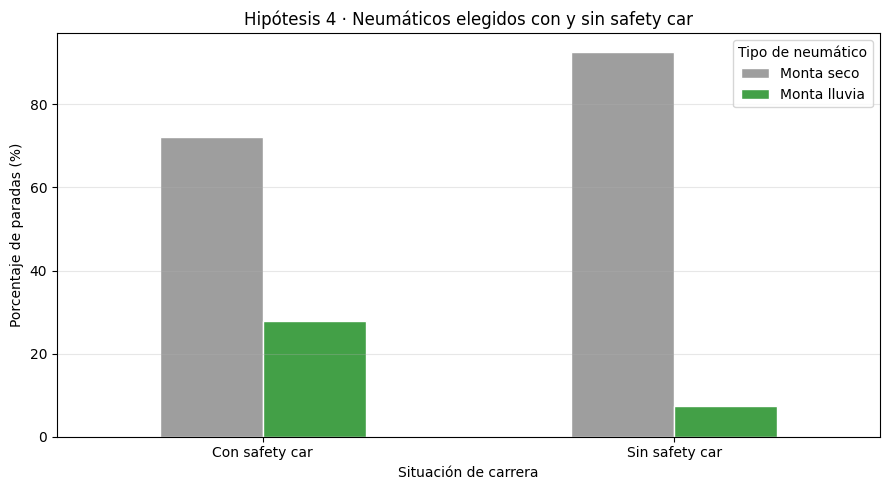


**Lectura de la hipótesis 4**

- Con safety car, el **27.9%**
  de las paradas monta neumáticos de lluvia.

- Sin safety car, el **7.4%**
  monta neumáticos de lluvia.

- Se registraron **75 paradas**
  con safety car donde se montaron neumáticos de lluvia.

- Las paradas con neumáticos de lluvia se distribuyen
  en **6 carreras**.

Los resultados muestran una asociación entre la presencia
del safety car y el uso de neumáticos INTERMEDIATE/WET.

Esto sugiere que parte de la relación observada
originalmente podría estar vinculada a condiciones
meteorológicas.

**Esta asociación no demuestra que el safety car cause
la elección del neumático.**


In [36]:
# ============================================================
# CORRECCIÓN 10 DE LA ENTREGA 2
# HIPÓTESIS 4: SAFETY CAR Y NEUMÁTICOS DE LLUVIA
# ============================================================

# Recuperamos la información descriptiva del Silver original.
# No agregamos safety_car_active a los modelos.

h4 = raw_pits[
    CLAVE + ["safety_car_active", "new_compound"]
].copy()

# Normalizamos la representación del indicador de safety car.
h4["safety_car"] = (
    h4["safety_car_active"]
    .astype("string")
    .str.lower()
    .eq("true")
)

# Clasificamos el compuesto elegido.
h4["tipo_neumatico"] = np.where(
    h4["new_compound"].isin(["INTERMEDIATE", "WET"]),
    "Monta lluvia",
    "Monta seco"
)

h4["situacion"] = np.where(
    h4["safety_car"],
    "Con safety car",
    "Sin safety car"
)


# ============================================================
# DISTRIBUCIÓN PORCENTUAL
# ============================================================

tabla_h4 = pd.crosstab(
    h4["situacion"],
    h4["tipo_neumatico"],
    normalize="index"
).mul(100).round(1)

# Incorporamos la cantidad de paradas y carreras.
tabla_h4["paradas"] = (
    h4["situacion"].value_counts()
)

tabla_h4["carreras"] = (
    h4.groupby("situacion")["session_key"].nunique()
)

display(tabla_h4)


# ============================================================
# ANÁLISIS DE LAS PARADAS CON LLUVIA
# ============================================================

lluvia_sc = h4[
    h4["tipo_neumatico"] == "Monta lluvia"
]

total_lluvia = len(lluvia_sc)

lluvia_con_sc = int(
    lluvia_sc["safety_car"].sum()
)

total_con_sc = int(
    h4["safety_car"].sum()
)

carreras_lluvia = (
    lluvia_sc["session_key"].nunique()
)

print(
    f"Paradas que montan INTERMEDIATE/WET: {total_lluvia}"
)

print(
    f"De ellas, {lluvia_con_sc} ocurrieron con safety car."
)

print(
    f"Carreras con paradas de lluvia: {carreras_lluvia}"
)

print(
    f"Paradas totales con safety car: {total_con_sc}"
)


# ============================================================
# GRÁFICO COMPARATIVO
# ============================================================

columnas_grafico = [
    "Monta seco",
    "Monta lluvia"
]

tabla_grafico = tabla_h4[
    columnas_grafico
]

ax = tabla_grafico.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#9e9e9e", "#43a047"],
    edgecolor="white"
)

ax.set_title(
    "Hipótesis 4 · Neumáticos elegidos con y sin safety car"
)

ax.set_xlabel("Situación de carrera")
ax.set_ylabel("Porcentaje de paradas (%)")

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=0
)

ax.legend(
    title="Tipo de neumático"
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# INTERPRETACIÓN AUTOMÁTICA
# ============================================================

porcentaje_con_sc = tabla_h4.loc[
    "Con safety car",
    "Monta lluvia"
]

porcentaje_sin_sc = tabla_h4.loc[
    "Sin safety car",
    "Monta lluvia"
]

display(Markdown(f"""
**Lectura de la hipótesis 4**

- Con safety car, el **{porcentaje_con_sc:.1f}%**
  de las paradas monta neumáticos de lluvia.

- Sin safety car, el **{porcentaje_sin_sc:.1f}%**
  monta neumáticos de lluvia.

- Se registraron **{lluvia_con_sc} paradas**
  con safety car donde se montaron neumáticos de lluvia.

- Las paradas con neumáticos de lluvia se distribuyen
  en **{carreras_lluvia} carreras**.

Los resultados muestran una asociación entre la presencia
del safety car y el uso de neumáticos INTERMEDIATE/WET.

Esto sugiere que parte de la relación observada
originalmente podría estar vinculada a condiciones
meteorológicas.

**Esta asociación no demuestra que el safety car cause
la elección del neumático.**
"""))

### Interpretación de la hipótesis 4

El análisis permite distinguir entre el efecto observado
del safety car y la presencia de neumáticos utilizados
en condiciones de lluvia.

En el trabajo original de la Entrega 2, nuestro compañero
identificó que el 27,9 % de las paradas con safety car
montaban neumáticos INTERMEDIATE/WET, mientras que
sin safety car esta proporción era del 7,4 %.

Estos resultados muestran que las condiciones meteorológicas
pueden estar relacionadas con la asociación observada.

Por lo tanto, no corresponde interpretar que la presencia
del safety car determina directamente la elección de
un compuesto más blando.

La lluvia puede estar asociada tanto a la aparición
del safety car como a la elección de neumáticos intermedios.

**Decisión para el modelado:**

Se mantiene `safety_car_active` fuera de las variables
predictoras, respetando la devolución de la Entrega 2.

El modelo utiliza otras características disponibles antes
de la decisión, como el estado de los neumáticos del pelotón,
la humedad y la información meteorológica histórica.

De esta manera, conservamos la corrección del análisis
exploratorio sin modificar la selección de variables
del modelo final.

## 2 · Ingeniería de variables **causales** compartidas
El procesamiento histórico se hace una sola vez, por carrera y piloto, para poder reutilizarlo en las dos etapas. **No se ajustan parámetros estadísticos con todo el dataset**: la imputación, el escalado y el one-hot sí pertenecen al `Pipeline` de sklearn y se vuelven a ajustar en cada fold. La generación de estados históricos se realiza previamente porque necesita la secuencia completa de vueltas, también necesaria al operar la aplicación; **es una etapa determinista externa** y por eso no afirmamos que absolutamente todo esté dentro del objeto sklearn.

Para no conocer el compuesto cambiado en la vuelta de parada, `compound_prev` y el resto del estado del piloto se calculan con la vuelta **t−1**; por prudencia eliminamos las vueltas iniciales sin historia suficiente. `stops_before` cuenta únicamente paradas anteriores. Las proporciones del pelotón se calculan sobre la vuelta anterior. No se utiliza `pit_stop` actual como característica.

In [37]:
def construir_historia(tabla):
    v = tabla.sort_values(CLAVE).copy()
    gp = v.groupby(['session_key','driver_number'],sort=False)
    origen = {'current_compound':'compound_prev','tyre_age':'tyre_age_prev',
              'position':'position_prev','rainfall':'rainfall_prev',
              'track_temperature':'track_temperature_prev',
              'air_temperature':'air_temperature_prev','humidity':'humidity_prev'}
    for col, nueva in origen.items():
        v[nueva] = gp[col].shift(1)
    v['stops_before'] = gp['pit_stop'].cumsum().astype(int) - v['pit_stop'].astype(int)
    for compuesto in ['SOFT','MEDIUM','HARD']:
        usado = v.current_compound.eq(compuesto).astype(float)
        v[f'used_{compuesto.lower()}'] = usado.groupby([v.session_key,v.driver_number]).transform(
            lambda s: s.shift(1).cummax())
    frac = pd.crosstab([v.session_key,v.lap_number],v.current_compound,normalize='index')
    for c in ['SOFT','MEDIUM','HARD','INTERMEDIATE','WET']:
        if c not in frac.columns: frac[c] = 0.0
    frac['LLUVIA'] = frac['INTERMEDIATE'] + frac['WET']
    frac = frac[['SOFT','MEDIUM','HARD','LLUVIA']].rename(columns=lambda c:f'field_{c.lower()}_prev').reset_index()
    frac.lap_number += 1
    v = v.merge(frac,on=['session_key','lap_number'],how='left',validate='many_to_one')
    return v

hist = construir_historia(vueltas)
# No inventamos el estado del neumático de entrada cuando no se vio ninguna vuelta anterior.
hist = hist.loc[hist.compound_prev.notna() & hist.tyre_age_prev.notna()].copy()
assert not hist.duplicated(CLAVE).any()
assert hist['stops_before'].ge(0).all()
NUM = ['lap_number','tyre_age_prev','position_prev','stops_before','track_temperature_prev',
       'air_temperature_prev','humidity_prev','used_soft','used_medium','used_hard',
       'field_soft_prev','field_medium_prev','field_hard_prev','field_lluvia_prev']
CAT = ['compound_prev','circuit_short_name','team_name','rainfall_prev']
FEATURES = NUM+CAT
PROHIBIDAS = {'pit_stop','new_compound','current_compound','stint_number','pit_duration',
              'lane_duration','stop_duration','session_max_lap_observed','lap_duration',
              'gap_to_leader_raw','safety_car_active','yellow_flag_active','interval_raw'}
assert not (set(FEATURES)&PROHIBIDAS)
# Enlazar los objetivos de compuesto por las tres claves: comprobar matches y ausencias.
objetivos = raw_pits[CLAVE+['new_compound']].copy()
objetivos['objetivo_compuesto'] = objetivos['new_compound'].replace({'INTERMEDIATE':'LLUVIA','WET':'LLUVIA'})
hist = hist.merge(objetivos[CLAVE+['objetivo_compuesto']],on=CLAVE,how='left',validate='one_to_one')
assert hist.loc[hist.pit_stop,'objetivo_compuesto'].notna().all(), 'Paradas sin compuesto en la vista Silver.'
assert hist.loc[hist.pit_stop,'objetivo_compuesto'].isin(ORDEN).all()
print('Observaciones con historia:',len(hist),'| Paradas con compuesto:',int(hist.pit_stop.sum()))
display(hist.groupby('season').agg(vueltas=('pit_stop','size'),paradas=('pit_stop','sum'),carreras=('session_key','nunique')))
display(hist.loc[hist.pit_stop,'objetivo_compuesto'].value_counts().reindex(ORDEN).to_frame('paradas'))

Observaciones con historia: 69472 | Paradas con compuesto: 2244


,vueltas,paradas,carreras
season,,,
2023,17534,657,16
2024,26151,785,24
2025,25787,802,24


,paradas
objetivo_compuesto,
SOFT,321
MEDIUM,631
HARD,1072
LLUVIA,220


## 2.1. Corrección de la hipótesis 1: edad del neumático y parada en boxes

En la Entrega 2 planteamos la siguiente hipótesis:

**H1: la edad del neumático influye en la decisión de realizar
una parada en boxes.**

Inicialmente utilizamos un boxplot para comparar la edad de
los neumáticos entre las vueltas con parada y sin parada.

A partir de la devolución del docente, reemplazamos ese
gráfico por un histograma.

El histograma permite observar con mayor claridad la
distribución de edades y detectar en qué intervalos
se concentran las paradas.

Para evitar utilizar información posterior al ingreso a boxes,
empleamos `tyre_age_prev`, que representa la edad del
neumático registrada en la vuelta anterior.

Como las vueltas sin parada son mucho más frecuentes,
normalizamos cada grupo por separado.

De esta manera, el gráfico compara la distribución
porcentual de ambos grupos sin que la diferencia de cantidad
de observaciones oculte sus patrones.

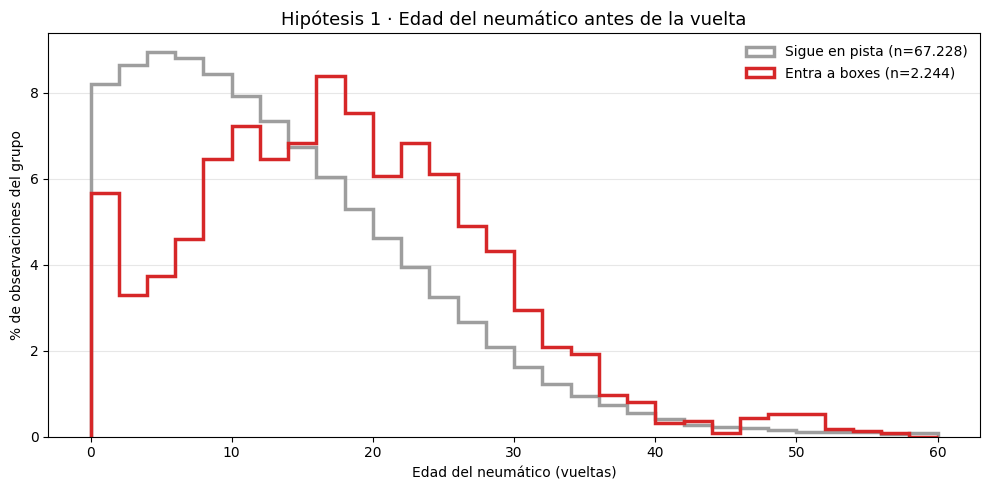

,count,25%,50%,75%
pit_stop,,,,
False,67228.0,5.0,11.0,19.0
True,2244.0,10.0,17.0,24.0



**Lectura de la hipótesis 1**

- Mediana sin parada: **11.0 vueltas**.
- Mediana con parada: **17.0 vueltas**.
- Diferencia entre medianas: **6.0 vueltas**.

El histograma permite comparar la distribución de la edad
del neumático en ambos grupos.

Una mediana mayor entre las vueltas con parada es consistente
con la hipótesis de que la edad del neumático está relacionada
con la decisión de ingresar a boxes.

Sin embargo, la superposición entre distribuciones indica
que la edad por sí sola no determina cuándo detenerse.


In [38]:
# ============================================================
# CORRECCIÓN 9 DE LA ENTREGA 2
# HIPÓTESIS 1: EDAD DEL NEUMÁTICO Y PARADAS
# ============================================================

# Utilizamos las observaciones con historia válida,
# preparadas previamente en la sección 2.

datos_histograma = hist[
    ["pit_stop", "tyre_age_prev"]
].copy()

# Convertimos la edad del neumático a valores numéricos.
datos_histograma["tyre_age_prev"] = pd.to_numeric(
    datos_histograma["tyre_age_prev"],
    errors="coerce"
)

# Definimos intervalos de dos vueltas.
bins = np.arange(0, 61, 2)

fig, ax = plt.subplots(figsize=(10, 5))

grupos = [
    (False, "Sigue en pista", "#9e9e9e"),
    (True, "Entra a boxes", "#d62728")
]

for valor, etiqueta, color in grupos:

    edades = datos_histograma.loc[
        datos_histograma["pit_stop"] == valor,
        "tyre_age_prev"
    ].dropna()

    # Cada grupo se normaliza independientemente.
    pesos = np.full(
        len(edades),
        100 / len(edades)
    )

    ax.hist(
        edades,
        bins=bins,
        weights=pesos,
        histtype="step",
        linewidth=2.5,
        color=color,
        label=f"{etiqueta} (n={len(edades):,})".replace(",", ".")
    )

ax.set_title(
    "Hipótesis 1 · Edad del neumático antes de la vuelta",
    fontsize=13
)

ax.set_xlabel("Edad del neumático (vueltas)")
ax.set_ylabel("% de observaciones del grupo")

ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()


# ============================================================
# RESUMEN ESTADÍSTICO
# ============================================================

resumen_edades = (
    datos_histograma
    .groupby("pit_stop")["tyre_age_prev"]
    .describe()[["count", "25%", "50%", "75%"]]
)

display(resumen_edades)


# ============================================================
# INTERPRETACIÓN AUTOMÁTICA
# ============================================================

mediana_sin = resumen_edades.loc[False, "50%"]
mediana_con = resumen_edades.loc[True, "50%"]

display(Markdown(f"""
**Lectura de la hipótesis 1**

- Mediana sin parada: **{mediana_sin:.1f} vueltas**.
- Mediana con parada: **{mediana_con:.1f} vueltas**.
- Diferencia entre medianas: **{mediana_con - mediana_sin:.1f} vueltas**.

El histograma permite comparar la distribución de la edad
del neumático en ambos grupos.

Una mediana mayor entre las vueltas con parada es consistente
con la hipótesis de que la edad del neumático está relacionada
con la decisión de ingresar a boxes.

Sin embargo, la superposición entre distribuciones indica
que la edad por sí sola no determina cuándo detenerse.
"""))

### Interpretación de la hipótesis 1

El histograma permite observar la distribución de la edad
del neumático antes de cada vuelta.

En el análisis original de nuestro compañero, las vueltas
con parada presentaban una distribución desplazada hacia
edades mayores respecto de las vueltas sin parada.

El cambio de visualización permite identificar mejor esta
diferencia y observar que también existen paradas con
neumáticos relativamente nuevos.

Estas situaciones pueden estar relacionadas con cambios
de estrategia, condiciones meteorológicas o incidentes,
aunque el gráfico por sí solo no permite determinar
cuál fue la causa de cada parada.

También existe superposición entre las dos distribuciones,
lo que indica que la edad del neumático no es suficiente
para decidir el momento de una parada.

**Relación con la Entrega 3:**

La importancia de esta variable se vuelve a evaluar
durante el modelado supervisado.

En particular, la sección 10 utiliza importancia por
permutación para medir cuánto disminuye el rendimiento
del clasificador cuando se altera `tyre_age_prev`.

De esta manera, conectamos el análisis exploratorio
de la Entrega 2 con los resultados del modelo de parada
de la Entrega 3.

## 3 · Métricas, piso, validación y modelos candidatos
**`pit_stop` (binario):** métrica principal **F1 de la clase positiva**, para que la clase mayoritaria NO_PIT no disimule los errores; adicionalmente se informan precisión, recall y accuracy. Una parada innecesaria cuesta tiempo y posiciones; una parada omitida puede deteriorar los neumáticos. Para la aplicación es importante inspeccionar especialmente los falsos positivos y el umbral de recomendación.

**`new_compound` (cuatro clases):** **F1 macro**, ya que SOFT y LLUVIA son minoritarias. Accuracy y balanced accuracy son métricas complementarias. Se agrupan INTERMEDIATE y WET únicamente para la evaluación del neumático como LLUVIA.

**Piso:** un `DummyClassifier` que siempre elige la clase mayoritaria, con la **misma validación** que el resto.  
**Partición:** temporadas 2023–2024 (entrenar/validar) vs. 2025 (evaluación final). **StratifiedGroupKFold** por `session_key` en el entrenamiento: no se reparten pilotos ni vueltas de una misma carrera entre train y validación. Una clase poco frecuente puede faltar en algún fold a pesar de la estratificación; se informa explícitamente.

**Candidatos:** regresión logística (modelo simple de referencia), árbol de decisión, random forest e HistGradientBoosting. Misma preparación y variables para comparación justa.

In [39]:
train = hist[hist.season.lt(2025)].reset_index(drop=True)
test  = hist[hist.season.eq(2025)].reset_index(drop=True)
assert set(train.session_key).isdisjoint(set(test.session_key))

def pipeline(modelo, nums=NUM, cats=CAT):
    transformer = ColumnTransformer([
        ('num',Pipeline([('imputar',SimpleImputer(strategy='median')),
                         ('escalar',StandardScaler())]),list(nums)),
        ('cat',Pipeline([('imputar',SimpleImputer(strategy='most_frequent')),
                         ('onehot',OneHotEncoder(handle_unknown='ignore', sparse_output=False))]),list(cats))])
    return Pipeline([('preparar',transformer),('modelo',modelo)])

def split_datos(tabla, solo_pits=False):
    v = tabla.loc[tabla.pit_stop].copy() if solo_pits else tabla.copy()
    return v[FEATURES].copy(), (v.objetivo_compuesto if solo_pits else v.pit_stop.astype(int)),v.session_key

Xpit, ypit, gpit = split_datos(train)
Xpit_test,ypit_test,_ = split_datos(test)
Xcomp,ycomp,gcomp = split_datos(train,True)
Xcomp_test,ycomp_test,_ = split_datos(test,True)
cvpit = StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)
cvcomp = StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)

def auditar_folds(X,y,gr,cv):
    filas=[]
    for i,(a,b) in enumerate(cv.split(X,y,gr),1):
        assert set(gr.iloc[a]).isdisjoint(set(gr.iloc[b]))
        fila={'fold':i,'filas_validacion':len(b),'carreras_validacion':gr.iloc[b].nunique(),
              'carreras_compartidas':0}
        fila.update({f'clase_{k}':int(v) for k,v in y.iloc[b].value_counts().items()})
        filas.append(fila)
    return pd.DataFrame(filas).fillna(0).set_index('fold')
print('PIT STOP:');display(auditar_folds(Xpit,ypit,gpit,cvpit))
print('COMPUESTO:');display(auditar_folds(Xcomp,ycomp,gcomp,cvcomp))

def familias():
    return {'Piso mayoría':DummyClassifier(strategy='most_frequent'),
            'Regresión logística':LogisticRegression(max_iter=3000,class_weight='balanced',random_state=SEED),
            'Árbol':DecisionTreeClassifier(max_depth=8,min_samples_leaf=20,class_weight='balanced',random_state=SEED),
            'Random forest':RandomForestClassifier(n_estimators=120,max_depth=12,min_samples_leaf=15,
                                                   class_weight='balanced_subsample',random_state=SEED,n_jobs=-1),
            'HistGradientBoosting':HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=15,
                                                                 class_weight='balanced',random_state=SEED)}

def comparar(X,y,gr,cv,metrica):
    filas=[]
    for nombre,estimador in familias().items():
        r=cross_validate(pipeline(estimador),X,y,groups=gr,cv=cv,scoring=metrica,n_jobs=1,error_score='raise')
        filas.append({'modelo':nombre,'F1 medio':r['test_score'].mean(),
                      'desvío':r['test_score'].std(ddof=0),
                      'folds':np.round(r['test_score'],3).tolist()})
    return pd.DataFrame(filas).set_index('modelo').sort_values('F1 medio',ascending=False)

comparacion_pit = comparar(Xpit,ypit,gpit,cvpit,'f1')
comparacion_comp = comparar(Xcomp,ycomp,gcomp,cvcomp,'f1_macro')
print('PIT STOP | F1 positivo:');display(comparacion_pit)
print('COMPUESTO | F1 macro:');display(comparacion_comp)

PIT STOP:


,filas_validacion,carreras_validacion,carreras_compartidas,clase_0,clase_1
fold,,,,,
1,8721,8,0,8411,310
2,8693,8,0,8350,343
3,8431,8,0,8156,275
4,9032,8,0,8716,316
5,8808,8,0,8610,198


COMPUESTO:


,filas_validacion,carreras_validacion,carreras_compartidas,clase_HARD,clase_MEDIUM,clase_SOFT,clase_LLUVIA
fold,,,,,,,
1,243,7,0,126,79,38,0.0
2,334,7,0,122,65,90,57.0
3,267,9,0,135,66,12,54.0
4,280,8,0,173,84,23,0.0
5,318,9,0,203,67,25,23.0


PIT STOP | F1 positivo:


,F1 medio,desvío,folds
modelo,,,
Random forest,0.138742,0.026937,"[0.164, 0.128, 0.177, 0.119, 0.107]"
HistGradientBoosting,0.125299,0.027799,"[0.157, 0.118, 0.152, 0.12, 0.08]"
Árbol,0.108749,0.018234,"[0.14, 0.106, 0.101, 0.111, 0.084]"
Regresión logística,0.092852,0.030726,"[0.108, 0.084, 0.126, 0.109, 0.038]"
Piso mayoría,0.000000,0.000000,"[0.0, 0.0, 0.0, 0.0, 0.0]"


COMPUESTO | F1 macro:


,F1 medio,desvío,folds
modelo,,,
Random forest,0.532909,0.107224,"[0.478, 0.546, 0.707, 0.554, 0.379]"
Árbol,0.468434,0.106665,"[0.569, 0.416, 0.41, 0.616, 0.331]"
HistGradientBoosting,0.460035,0.079873,"[0.475, 0.367, 0.479, 0.592, 0.387]"
Regresión logística,0.415295,0.073164,"[0.478, 0.343, 0.385, 0.525, 0.346]"
Piso mayoría,0.195748,0.042656,"[0.228, 0.134, 0.168, 0.255, 0.195]"


### Lectura de la comparación
Las tablas de arriba son **resultados calculados**, no valores copiados de la versión previa. Se informa la media y el desvío de los cinco folds. Una mejora pequeña respecto de la desviación puede deberse al reparto de carreras; por eso ajustamos y comparamos de nuevo los finalistas con las mismas particiones. Un buen F1 en test no se usa para seleccionar el modelo.

## 4 · Desbalance y ablación de variables (solo entrenamiento)
Se compara la regresión logística con y sin `class_weight='balanced'`. También se mide el efecto de eliminar `tyre_age_prev`, `compound_prev`, `position_prev` y las proporciones de compuestos del pelotón. **No se eliminan columnas solo porque un experimento aislado cambie unos milésimos de F1**: se reportan media y desvío y se justifica por dominio.

In [40]:
def ablar(X,y,g,cv,scoring):
    pruebas=[]
    configuraciones = [('Logística sin pesos',NUM,CAT,None),('Logística balanceada',NUM,CAT,'balanced')]
    configuraciones += [(f'Sin {c}',[x for x in NUM if x!=c],[x for x in CAT if x!=c],'balanced')
                        for c in ['tyre_age_prev','compound_prev','position_prev']]
    configuraciones += [('Sin pelotón',[x for x in NUM if not x.startswith('field_')],CAT,'balanced')]
    for nombre,nums,cats,peso in configuraciones:
        estimador=pipeline(LogisticRegression(C=0.03,max_iter=3000,class_weight=peso,random_state=SEED),nums,cats)
        r=cross_validate(estimador,X,y,groups=g,cv=cv,scoring=scoring,n_jobs=1,error_score='raise')['test_score']
        pruebas.append({'experimento':nombre,'F1 medio':r.mean(),'desvío':r.std(ddof=0)})
    return pd.DataFrame(pruebas).set_index('experimento')
print('PIT STOP:');display(ablar(Xpit,ypit,gpit,cvpit,'f1').round(4))
print('COMPUESTO:');display(ablar(Xcomp,ycomp,gcomp,cvcomp,'f1_macro').round(4))

PIT STOP:


,F1 medio,desvío
experimento,,
Logística sin pesos,0.0124,0.0215
Logística balanceada,0.1069,0.0339
Sin tyre_age_prev,0.0934,0.0286
Sin compound_prev,0.1061,0.0336
Sin position_prev,0.1071,0.0348
Sin pelotón,0.1066,0.0348


COMPUESTO:


,F1 medio,desvío
experimento,,
Logística sin pesos,0.4182,0.0521
Logística balanceada,0.4431,0.1041
Sin tyre_age_prev,0.4528,0.0807
Sin compound_prev,0.4321,0.0997
Sin position_prev,0.4402,0.1017
Sin pelotón,0.4443,0.0511


## 5 · Ajuste de hiperparámetros: modelos simple y complejo
Se ajustan **ambos finalistas**, no solo el complejo. `GridSearchCV` usa exactamente la validación por carrera y devuelve la **tabla completa** de combinaciones, sus F1 de validación, desvíos y F1 de entrenamiento. Un F1 de entrenamiento mucho mayor que el de validación es señal de sobreajuste.

La selección final empleará una regla didáctica **explícita y simétrica**: conservar el bosque únicamente si su ventaja media sobre la logística supera el desvío de las diferencias pareadas entre los mismos folds; en caso contrario, conservar la logística. Esta regla es un criterio práctico de la cátedra, **no una prueba de equivalencia estadística**.

In [41]:
def ajustar_finalistas(X,y,g,cv,score):
    grids={
      'Regresión logística':(LogisticRegression(max_iter=3000,random_state=SEED),
         {'modelo__C':[0.003,0.03,0.3,3], 'modelo__class_weight':[None,'balanced']}),
      'Random forest':(RandomForestClassifier(n_estimators=150,random_state=SEED,n_jobs=-1),
         {'modelo__max_depth':[8,16], 'modelo__min_samples_leaf':[8,25],
          'modelo__class_weight':[None,'balanced_subsample']})}
    encontrados={}; filas=[]
    for nombre,(modelo,parametros) in grids.items():
        grid=GridSearchCV(pipeline(modelo),parametros,scoring=score,cv=cv,
                          n_jobs=1,refit=True,return_train_score=True,error_score='raise')
        grid.fit(X,y,groups=g)
        encontrados[nombre]=grid
        t=pd.DataFrame(grid.cv_results_)[['params','mean_test_score','std_test_score','mean_train_score','rank_test_score']]
        t.insert(0,'modelo',nombre)
        filas.append(t)
        print(nombre,'| mejor F1:',round(grid.best_score_,4),'| parámetros:',grid.best_params_)
    display(pd.concat(filas,ignore_index=True).sort_values(['modelo','rank_test_score']).reset_index(drop=True))
    return encontrados

print('AJUSTE PIT STOP'); grids_pit=ajustar_finalistas(Xpit,ypit,gpit,cvpit,'f1')
print('AJUSTE COMPUESTO'); grids_comp=ajustar_finalistas(Xcomp,ycomp,gcomp,cvcomp,'f1_macro')

AJUSTE PIT STOP
Regresión logística | mejor F1: 0.1164 | parámetros: {'modelo__C': 0.003, 'modelo__class_weight': 'balanced'}
Random forest | mejor F1: 0.1449 | parámetros: {'modelo__class_weight': 'balanced_subsample', 'modelo__max_depth': 16, 'modelo__min_samples_leaf': 25}


,modelo,params,mean_test_score,std_test_score,mean_train_score,rank_test_score
0,Random forest,"{'modelo__class_weight': 'balanced_subsample',...",0.144933,0.030606,0.308425,1
1,Random forest,"{'modelo__class_weight': 'balanced_subsample',...",0.141193,0.021389,0.414275,2
2,Random forest,"{'modelo__class_weight': 'balanced_subsample',...",0.134161,0.026002,0.228311,3
3,Random forest,"{'modelo__class_weight': 'balanced_subsample',...",0.132845,0.025757,0.217905,4
4,Random forest,"{'modelo__class_weight': None, 'modelo__max_de...",0.000000,0.000000,0.023025,5
5,Random forest,"{'modelo__class_weight': None, 'modelo__max_de...",0.000000,0.000000,0.000000,5
6,Random forest,"{'modelo__class_weight': None, 'modelo__max_de...",0.000000,0.000000,0.113481,5
7,Random forest,"{'modelo__class_weight': None, 'modelo__max_de...",0.000000,0.000000,0.000000,5
8,Regresión logística,"{'modelo__C': 0.003, 'modelo__class_weight': '...",0.116382,0.029893,0.130143,1
9,Regresión logística,"{'modelo__C': 0.03, 'modelo__class_weight': 'b...",0.106851,0.033882,0.141284,2


AJUSTE COMPUESTO
Regresión logística | mejor F1: 0.4737 | parámetros: {'modelo__C': 0.003, 'modelo__class_weight': 'balanced'}
Random forest | mejor F1: 0.536 | parámetros: {'modelo__class_weight': 'balanced_subsample', 'modelo__max_depth': 16, 'modelo__min_samples_leaf': 25}


,modelo,params,mean_test_score,std_test_score,mean_train_score,rank_test_score
0,Random forest,"{'modelo__class_weight': 'balanced_subsample',...",0.536012,0.099238,0.734391,1
1,Random forest,"{'modelo__class_weight': 'balanced_subsample',...",0.533520,0.094636,0.731717,2
2,Random forest,"{'modelo__class_weight': 'balanced_subsample',...",0.498439,0.074571,0.858014,3
3,Random forest,"{'modelo__class_weight': 'balanced_subsample',...",0.490200,0.075588,0.843072,4
4,Random forest,"{'modelo__class_weight': None, 'modelo__max_de...",0.435473,0.102719,0.803773,5
5,Random forest,"{'modelo__class_weight': None, 'modelo__max_de...",0.433202,0.083382,0.826107,6
6,Random forest,"{'modelo__class_weight': None, 'modelo__max_de...",0.381838,0.044827,0.675734,7
7,Random forest,"{'modelo__class_weight': None, 'modelo__max_de...",0.378181,0.049243,0.679921,8
8,Regresión logística,"{'modelo__C': 0.003, 'modelo__class_weight': '...",0.473687,0.141161,0.650001,1
9,Regresión logística,"{'modelo__C': 0.03, 'modelo__class_weight': 'b...",0.443122,0.104128,0.691570,2


## 6 · Comparación pareada agrupada repetida y elección
Repetimos `GroupKFold(shuffle=True)` sobre **2023–2024** con tres semillas, cinco folds cada una (15 evaluaciones por candidato). Son mediciones de sensibilidad entre particiones: **no son 15 muestras estadísticamente independientes**. Se comparan folds idénticos, con la diferencia `Random forest − Regresión logística`. Los estimadores ajustados se reentrenan en cada fold de esta evaluación; el ajuste de hiperparámetros se eligió previamente con las grillas del apartado anterior, por lo que esta comparación es descriptiva y no una validación anidada.

In [42]:
def repetir_y_elegir(grids,X,y,g,score):
    puntajes={k:[] for k in grids}
    for rep in range(3):
        cv=GroupKFold(n_splits=5,shuffle=True,random_state=SEED+rep)
        for nombre,grid in grids.items():
            valores=cross_validate(clone(grid.best_estimator_),X,y,groups=g,cv=cv,
                                   scoring=score,n_jobs=1,error_score='raise')['test_score']
            puntajes[nombre].extend(valores.tolist())
    t=pd.DataFrame(puntajes)
    d=t['Random forest']-t['Regresión logística']
    resumen=pd.DataFrame({'media':t.mean(),'desvío':t.std(ddof=0)})
    resumen.loc['Diferencia RF − logística']=[d.mean(),d.std(ddof=0)]
    display(resumen.round(4))
    elegido='Random forest' if d.mean()>max(0,d.std(ddof=0)) else 'Regresión logística'
    display(Markdown(f'**Elección por validación:** `{elegido}`. Diferencia bosque − logística: '
                     f'**{d.mean():+.4f} ± {d.std(ddof=0):.4f}**; gana en **{(d>0).mean():.0%}** de los folds.'))
    return elegido,grids[elegido].best_estimator_,resumen

print('PIT STOP'); elegido_pit,modelo_pit,res_pit=repetir_y_elegir(grids_pit,Xpit,ypit,gpit,'f1')
print('COMPUESTO'); elegido_comp,modelo_comp,res_comp=repetir_y_elegir(grids_comp,Xcomp,ycomp,gcomp,'f1_macro')

PIT STOP


,media,desvío
Regresión logística,0.1112,0.0165
Random forest,0.1443,0.0260
Diferencia RF − logística,0.0330,0.0155


**Elección por validación:** `Random forest`. Diferencia bosque − logística: **+0.0330 ± 0.0155**; gana en **100%** de los folds.

COMPUESTO


,media,desvío
Regresión logística,0.4852,0.0964
Random forest,0.5441,0.1021
Diferencia RF − logística,0.0589,0.0801


**Elección por validación:** `Regresión logística`. Diferencia bosque − logística: **+0.0589 ± 0.0801**; gana en **60%** de los folds.

## 7 · Umbral para recomendar parada (solo validación de entrenamiento)
Para `pit_stop`, el `.predict()` habitual usa el umbral predeterminado. Con clases muy desparejas ese umbral puede producir **muchas recomendaciones de paradas que no ocurren**. Comparamos umbrales entre 0,10 y 0,90 sobre probabilidades **out-of-fold** del entrenamiento. Elegimos el máximo F1 de la clase positiva; en caso de empate, priorizamos el umbral más alto (menos falsas alarmas). Guardamos además la precisión y recall del umbral elegido, comparados con 0,50.

Esta optimización ocurre **sin consultar 2025**. Las probabilidades provenientes de modelos con pesos de clase pueden no estar calibradas; por ello, un 0,70 debe leerse como score del clasificador, no necesariamente como 70 % de probabilidad real.

,umbral,F1,precision,recall,paradas_predichas
18,0.550,0.1446,0.0893,0.3793,6124
19,0.575,0.1430,0.0907,0.3370,5356
17,0.525,0.1420,0.0855,0.4189,7067
20,0.600,0.1382,0.0913,0.2836,4478
16,0.500,0.1370,0.0805,0.4591,8222
21,0.625,0.1352,0.0956,0.2309,3485
15,0.475,0.1346,0.0778,0.4993,9259
14,0.450,0.1314,0.0749,0.5354,10305
13,0.425,0.1286,0.0725,0.5693,11322
22,0.650,0.1284,0.0994,0.1810,2625


Umbral elegido SOLO en CV: 0.55


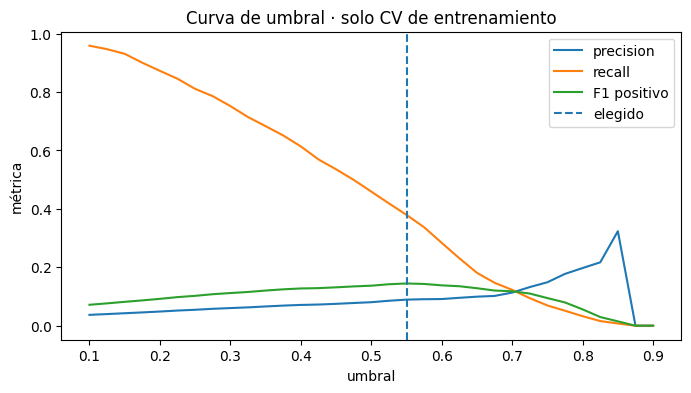

In [43]:
probas_pit_oof = cross_val_predict(clone(modelo_pit),Xpit,ypit,groups=gpit,cv=cvpit,
                                   method='predict_proba',n_jobs=1)[:,1]
umbrales=np.round(np.arange(.10,.901,.025),3)
tabla_umbrales=pd.DataFrame([{'umbral':u,'F1':f1_score(ypit,probas_pit_oof>=u,zero_division=0),
    'precision':precision_score(ypit,probas_pit_oof>=u,zero_division=0),
    'recall':recall_score(ypit,probas_pit_oof>=u,zero_division=0),
    'paradas_predichas':int((probas_pit_oof>=u).sum())} for u in umbrales])
mejor_f1=tabla_umbrales.F1.max()
UMBRAL_PIT=float(tabla_umbrales.loc[np.isclose(tabla_umbrales.F1,mejor_f1),'umbral'].max())
display(tabla_umbrales.sort_values('F1',ascending=False).head(12).round(4))
print('Umbral elegido SOLO en CV:',UMBRAL_PIT)
fig,ax=plt.subplots(figsize=(8,4));ax.plot(tabla_umbrales.umbral,tabla_umbrales.precision,label='precision')
ax.plot(tabla_umbrales.umbral,tabla_umbrales.recall,label='recall')
ax.plot(tabla_umbrales.umbral,tabla_umbrales.F1,label='F1 positivo')
ax.axvline(UMBRAL_PIT,linestyle='--',label='elegido');ax.set(xlabel='umbral',ylabel='métrica',title='Curva de umbral · solo CV de entrenamiento');ax.legend();plt.show()

## 8 · Evaluación final **una sola vez** sobre 2025
En este bloque recién se consulta 2025 para reportar resultados. **No usar estas métricas para modificar los modelos elegidos, las variables ni el umbral.** Se compara con el piso y se muestran las matrices de confusión normalizadas **por fila (recall)** y **por columna (precisión)**, además del reporte por clase. Un desempeño alto en `new_compound` sobre paradas reales no implica que el sistema completo sea igual de bueno: la primera etapa puede fallar.

PIT STOP · TEST 2025


,modelo final,piso NO_PIT
F1 positivo,0.1513,0.0000
precision,0.0924,0.0000
recall,0.4177,0.0000
accuracy,0.8543,0.9689


              precision    recall  f1-score   support

           0       0.98      0.87      0.92     24985
           1       0.09      0.42      0.15       802

    accuracy                           0.85     25787
   macro avg       0.54      0.64      0.54     25787
weighted avg       0.95      0.85      0.90     25787

COMPUESTO · TEST 2025 (solo paradas reales)


,modelo final,piso mayoría
F1 macro,0.6500,0.1404
accuracy,0.6683,0.3903
accuracy balanceada,0.6810,0.2500


              precision    recall  f1-score   support

        SOFT       0.49      0.53      0.51       133
      MEDIUM       0.70      0.59      0.64       270
        HARD       0.76      0.74      0.75       313
      LLUVIA       0.59      0.86      0.70        86

    accuracy                           0.67       802
   macro avg       0.64      0.68      0.65       802
weighted avg       0.68      0.67      0.67       802



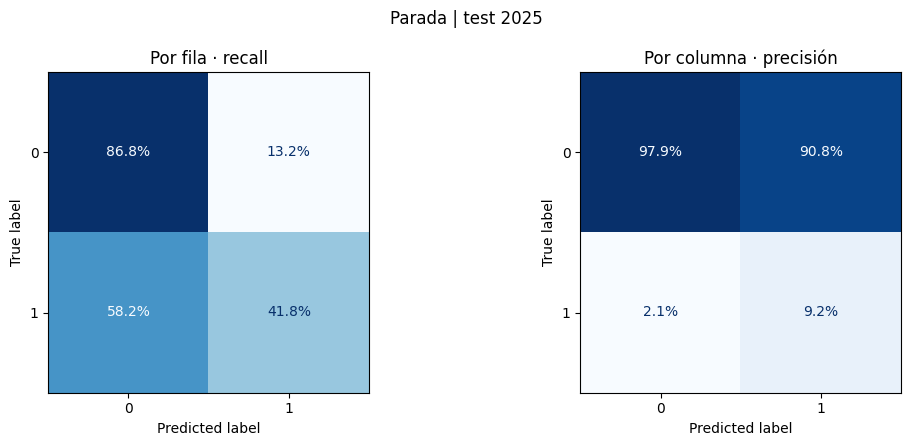

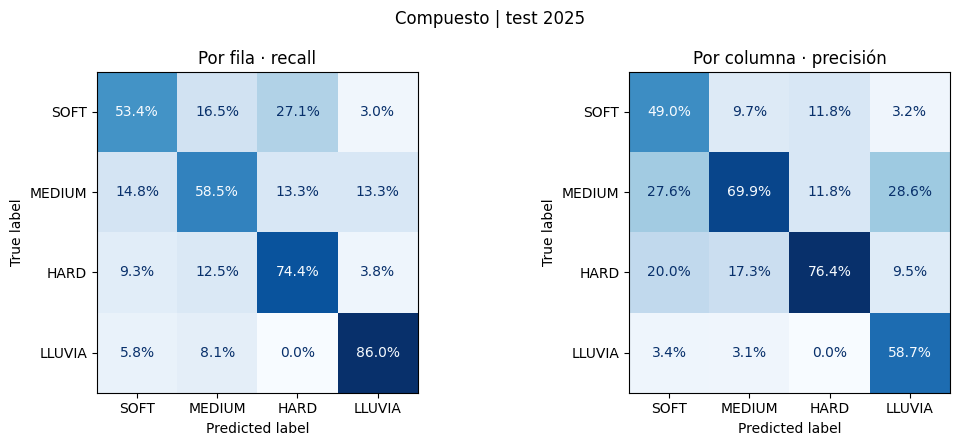

In [44]:
pred_pit=(modelo_pit.predict_proba(Xpit_test)[:,1]>=UMBRAL_PIT).astype(int)
pred_comp=modelo_comp.predict(Xcomp_test)
piso_pit=np.zeros(len(ypit_test),dtype=int)
piso_comp=pipeline(DummyClassifier(strategy='most_frequent')).fit(Xcomp,ycomp).predict(Xcomp_test)

print('PIT STOP · TEST 2025')
res_pit_test={
    'F1 positivo':f1_score(ypit_test,pred_pit,zero_division=0),
    'precision':precision_score(ypit_test,pred_pit,zero_division=0),
    'recall':recall_score(ypit_test,pred_pit,zero_division=0),
    'accuracy':accuracy_score(ypit_test,pred_pit)}
display(pd.DataFrame({'modelo final':res_pit_test,'piso NO_PIT':{
    'F1 positivo':f1_score(ypit_test,piso_pit,zero_division=0),
    'precision':0,'recall':0,'accuracy':accuracy_score(ypit_test,piso_pit)}}).round(4))
print(classification_report(ypit_test,pred_pit,labels=[0,1],zero_division=0))
print('COMPUESTO · TEST 2025 (solo paradas reales)')
res_comp_test={'F1 macro':f1_score(ycomp_test,pred_comp,average='macro',zero_division=0),
    'accuracy':accuracy_score(ycomp_test,pred_comp),
    'accuracy balanceada':balanced_accuracy_score(ycomp_test,pred_comp)}
display(pd.DataFrame({'modelo final':res_comp_test,'piso mayoría':{
    'F1 macro':f1_score(ycomp_test,piso_comp,average='macro',zero_division=0),
    'accuracy':accuracy_score(ycomp_test,piso_comp),
    'accuracy balanceada':balanced_accuracy_score(ycomp_test,piso_comp)}}).round(4))
print(classification_report(ycomp_test,pred_comp,labels=ORDEN,zero_division=0))

def matrices(y,pred,clases,titulo):
    fig,ax=plt.subplots(1,2,figsize=(11,4.5))
    for a,norm,nombre in zip(ax,['true','pred'],['Por fila · recall','Por columna · precisión']):
        ConfusionMatrixDisplay.from_predictions(y,pred,labels=clases,normalize=norm,
                        cmap='Blues',ax=a,colorbar=False,values_format='.1%')
        a.set_title(nombre)
    fig.suptitle(titulo);plt.tight_layout();plt.show()
matrices(ypit_test,pred_pit,[0,1],'Parada | test 2025')
matrices(ycomp_test,pred_comp,ORDEN,'Compuesto | test 2025')

## 9 · ¿Dónde se equivoca y por qué?
Se informa la cantidad de falsos positivos y falsos negativos de `pit_stop`, además de la precisión real de las alertas. Una **falsa parada** representa un ingreso innecesario a boxes; una **parada omitida**, una estrategia real que el clasificador no anticipó. Un error específico del compuesto se analiza mostrando carrera, piloto, vuelta, compuesto de entrada, compuesto real y recomendado. Estas tablas permiten contrastar hipótesis de dominio sin inventar causas que los datos no prueban.

In [45]:
lectura_pit=test.assign(pred_pit=pred_pit)
lectura_pit['error']=np.select([~lectura_pit.pit_stop & lectura_pit.pred_pit.eq(1),
                               lectura_pit.pit_stop & lectura_pit.pred_pit.eq(0)],
                              ['falsa parada','parada omitida'],default='otro')
print('Errores de detección:');display(lectura_pit.error.value_counts().to_frame('vueltas'))
print('Falsas paradas por tramo de vueltas:')
lectura_pit['tramo']=pd.cut(lectura_pit.lap_number,[0,10,20,35,50,100],include_lowest=True)
display(pd.crosstab(lectura_pit.tramo,lectura_pit.error).fillna(0))
print('Casos concretos de falsas paradas:')
display(lectura_pit.loc[lectura_pit.error.eq('falsa parada'),
    ['meeting_name','full_name','lap_number','tyre_age_prev','compound_prev','stops_before']].head(12))
comp_lectura=test.loc[test.pit_stop].copy().assign(predicho=pred_comp)
comp_lectura['acierto']=comp_lectura.objetivo_compuesto.eq(comp_lectura.predicho)
print('Acierto por compuesto de entrada:')
display(comp_lectura.groupby('compound_prev').acierto.agg(['size','mean']).round(3))
print('Casos concretos de compuesto equivocado:')
display(comp_lectura.loc[~comp_lectura.acierto,['meeting_name','full_name','lap_number',
    'compound_prev','tyre_age_prev','objetivo_compuesto','predicho']].head(15))

# Lectura actualizada: la genera el resultado, no un Markdown con números fijos.
fp=int(((ypit_test==0)&(pred_pit==1)).sum());fn=int(((ypit_test==1)&(pred_pit==0)).sum())
display(Markdown(f'**Lectura de los errores de parada:** {fp:,} falsas recomendaciones de parar y '
                 f'{fn:,} paradas reales no identificadas en las vueltas de 2025. '
                 f'La precisión es {res_pit_test["precision"]:.1%}; por eso **no debe utilizarse como orden automática de entrar a boxes**.'))

Errores de detección:


,vueltas
error,
otro,22030
falsa parada,3290
parada omitida,467


Falsas paradas por tramo de vueltas:


error,falsa parada,otro,parada omitida
tramo,,,
"(-0.001, 10.0]",205,3665,101
"(10.0, 20.0]",1094,3209,61
"(20.0, 35.0]",1397,5165,94
"(35.0, 50.0]",593,5764,96
"(50.0, 100.0]",1,4227,115


Casos concretos de falsas paradas:


,meeting_name,full_name,lap_number,tyre_age_prev,compound_prev,stops_before
145,Australian Grand Prix,Gabriel BORTOLETO,34,33.0,MEDIUM,4
146,Australian Grand Prix,Gabriel BORTOLETO,35,34.0,MEDIUM,4
147,Australian Grand Prix,Gabriel BORTOLETO,36,35.0,MEDIUM,4
148,Australian Grand Prix,Gabriel BORTOLETO,37,36.0,MEDIUM,4
149,Australian Grand Prix,Gabriel BORTOLETO,38,37.0,MEDIUM,4
150,Australian Grand Prix,Gabriel BORTOLETO,39,38.0,MEDIUM,4
151,Australian Grand Prix,Gabriel BORTOLETO,40,39.0,MEDIUM,4
152,Australian Grand Prix,Gabriel BORTOLETO,41,40.0,MEDIUM,4
153,Australian Grand Prix,Gabriel BORTOLETO,42,41.0,MEDIUM,4
154,Australian Grand Prix,Gabriel BORTOLETO,43,42.0,MEDIUM,4


Acierto por compuesto de entrada:


,size,mean
compound_prev,,
HARD,207,0.638
INTERMEDIATE,114,0.553
MEDIUM,360,0.706
SOFT,121,0.719


Casos concretos de compuesto equivocado:


,meeting_name,full_name,lap_number,compound_prev,tyre_age_prev,objetivo_compuesto,predicho
32,Australian Grand Prix,Max VERSTAPPEN,34,INTERMEDIATE,29.0,MEDIUM,LLUVIA
88,Australian Grand Prix,Lando NORRIS,34,INTERMEDIATE,29.0,HARD,LLUVIA
98,Australian Grand Prix,Lando NORRIS,44,HARD,10.0,LLUVIA,MEDIUM
155,Australian Grand Prix,Gabriel BORTOLETO,44,MEDIUM,43.0,LLUVIA,SOFT
189,Australian Grand Prix,Pierre GASLY,33,INTERMEDIATE,32.0,HARD,LLUVIA
245,Australian Grand Prix,Kimi ANTONELLI,33,INTERMEDIATE,32.0,HARD,LLUVIA
256,Australian Grand Prix,Kimi ANTONELLI,44,HARD,10.0,LLUVIA,MEDIUM
334,Australian Grand Prix,Charles LECLERC,34,INTERMEDIATE,33.0,HARD,LLUVIA
389,Australian Grand Prix,Lance STROLL,33,INTERMEDIATE,32.0,HARD,LLUVIA
400,Australian Grand Prix,Lance STROLL,44,HARD,11.0,LLUVIA,MEDIUM


**Lectura de los errores de parada:** 3,290 falsas recomendaciones de parar y 467 paradas reales no identificadas en las vueltas de 2025. La precisión es 9.2%; por eso **no debe utilizarse como orden automática de entrar a boxes**.

## 10 · ¿En qué variables se apoya? Importancia fuera de entrenamiento
Se calcula la importancia por permutación **en los folds de validación** de 2023–2024 para cada objetivo, no sobre las mismas filas usadas para ajustar el modelo. Así se reduce la interpretación sesgada por sobreajuste. La importancia es la caída de la métrica cuando se permuta una columna; con variables correlacionadas puede repartirse entre ellas y **no implica causalidad**.

**Chequeo temporal de la variable principal:** las variables con sufijo `_prev` proceden estrictamente de `shift(1)` por piloto y carrera, `used_*` de un máximo acumulado desplazado, `stops_before` de paradas anteriores y `field_*_prev` del pelotón en la vuelta anterior. Si predominara una columna sorprendente, habría que auditar el join y el significado antes de interpretarla como descubrimiento.

In [46]:
def importancia_validacion(modelo,X,y,g,cv,scoring):
    resultados=[]
    for tr,va in cv.split(X,y,g):
        est=clone(modelo).fit(X.iloc[tr],y.iloc[tr])
        p=permutation_importance(est,X.iloc[va],y.iloc[va],scoring=scoring,
                                 n_repeats=3,random_state=SEED,n_jobs=1)
        resultados.append(p.importances_mean)
    t=pd.DataFrame(resultados,columns=X.columns)
    return pd.DataFrame({'caída F1 media':t.mean(),'desvío':t.std(ddof=0),
                         'folds con caída positiva':(t>0).sum()}).sort_values('caída F1 media',ascending=False)

print('PIT STOP:')
imp_pit=importancia_validacion(modelo_pit,Xpit,ypit,gpit,cvpit,'f1')
display(imp_pit.round(4))
print('COMPUESTO:')
imp_comp=importancia_validacion(modelo_comp,Xcomp,ycomp,gcomp,cvcomp,'f1_macro')
display(imp_comp.round(4))
display(Markdown('**Variables más influyentes en CV:** parada = '
                 f'`{imp_pit.index[0]}` (caída media {imp_pit.iloc[0,0]:.3f}); '
                 f'compuesto = `{imp_comp.index[0]}` (caída media {imp_comp.iloc[0,0]:.3f}). '
                 'La importancia por permutación no es una prueba de causalidad.'))

PIT STOP:


,caída F1 media,desvío,folds con caída positiva
tyre_age_prev,0.0353,0.0132,5
stops_before,0.0181,0.0134,5
used_hard,0.0142,0.0120,5
compound_prev,0.0090,0.0106,4
lap_number,0.0063,0.0092,4
circuit_short_name,0.0028,0.0043,4
track_temperature_prev,0.0023,0.0046,3
used_medium,0.0023,0.0031,3
field_soft_prev,0.0023,0.0027,4
position_prev,0.0013,0.0019,3


COMPUESTO:


,caída F1 media,desvío,folds con caída positiva
used_medium,0.0613,0.0458,5
field_lluvia_prev,0.0378,0.0640,3
lap_number,0.0284,0.0690,4
track_temperature_prev,0.0229,0.0430,2
humidity_prev,0.0188,0.0135,5
used_hard,0.0180,0.0228,4
air_temperature_prev,0.0167,0.0248,4
field_hard_prev,0.0139,0.0409,3
tyre_age_prev,0.0072,0.0123,3
circuit_short_name,0.0043,0.0050,4


**Variables más influyentes en CV:** parada = `tyre_age_prev` (caída media 0.035); compuesto = `used_medium` (caída media 0.061). La importancia por permutación no es una prueba de causalidad.

## 11 · Evaluación de extremo a extremo: dos etapas
**Definición operacional:** en cada vuelta con historia disponible, el sistema primero calcula si recomienda parada. **Solo cuando recomienda parar** ofrece un compuesto. Esta evaluación evita la confusión entre medir `new_compound` únicamente en paradas verdaderas y medir **todo el recomendador**.

Reportamos: tasa de vueltas con propuesta de parada, precision/recall de parada y porcentaje de acierto del compuesto **entre las paradas reales correctamente detectadas**; este último valor debe interpretarse junto con la cantidad de paradas detectadas. También mostramos el porcentaje de todas las paradas reales para las que se acierta **ambas decisiones**. Nunca se atribuye al sistema integrado el F1 de compuesto condicionado a paradas reales.

In [47]:
prob_comp_total=modelo_comp.predict_proba(Xpit_test)
clases_comp=modelo_comp.named_steps['modelo'].classes_
comp_recomendado=clases_comp[np.argmax(prob_comp_total,axis=1)]
salida=test[CLAVE+['season','meeting_name','full_name','pit_stop','objetivo_compuesto']].copy()
salida['recomendar_pit']=pred_pit.astype(bool)
salida['compuesto_recomendado']=np.where(salida.recomendar_pit,comp_recomendado,'NO_APLICA')
detectadas=salida.pit_stop & salida.recomendar_pit
ambas_correctas=detectadas & salida.objetivo_compuesto.eq(salida.compuesto_recomendado)
res_sistema=pd.Series({
    'vueltas evaluadas':len(salida),
    'paradas reales':int(salida.pit_stop.sum()),
    'vueltas con parada recomendada':int(salida.recomendar_pit.sum()),
    'paradas reales correctamente detectadas':int(detectadas.sum()),
    'ambas decisiones correctas':int(ambas_correctas.sum()),
    'fracción de paradas reales con ambas decisiones correctas':float(ambas_correctas.sum()/salida.pit_stop.sum()),
    'acierto compuesto entre paradas reales detectadas':float(ambas_correctas.sum()/detectadas.sum()) if detectadas.sum() else np.nan})
display(res_sistema.to_frame('test 2025'))
print('Ejemplo de respuestas del sistema:')
display(salida.loc[salida.recomendar_pit].head(10))

,test 2025
vueltas evaluadas,25787.000000
paradas reales,802.000000
vueltas con parada recomendada,3625.000000
paradas reales correctamente detectadas,335.000000
ambas decisiones correctas,256.000000
fracción de paradas reales con ambas decisiones correctas,0.319202
acierto compuesto entre paradas reales detectadas,0.764179


Ejemplo de respuestas del sistema:


,session_key,driver_number,lap_number,season,meeting_name,full_name,pit_stop,objetivo_compuesto,recomendar_pit,compuesto_recomendado
32,9693,1,34,2025,Australian Grand Prix,Max VERSTAPPEN,True,MEDIUM,True,LLUVIA
88,9693,4,34,2025,Australian Grand Prix,Lando NORRIS,True,HARD,True,LLUVIA
145,9693,5,34,2025,Australian Grand Prix,Gabriel BORTOLETO,False,NaN,True,LLUVIA
146,9693,5,35,2025,Australian Grand Prix,Gabriel BORTOLETO,False,NaN,True,SOFT
147,9693,5,36,2025,Australian Grand Prix,Gabriel BORTOLETO,False,NaN,True,SOFT
148,9693,5,37,2025,Australian Grand Prix,Gabriel BORTOLETO,False,NaN,True,SOFT
149,9693,5,38,2025,Australian Grand Prix,Gabriel BORTOLETO,False,NaN,True,SOFT
150,9693,5,39,2025,Australian Grand Prix,Gabriel BORTOLETO,False,NaN,True,SOFT
151,9693,5,40,2025,Australian Grand Prix,Gabriel BORTOLETO,False,NaN,True,SOFT
152,9693,5,41,2025,Australian Grand Prix,Gabriel BORTOLETO,False,NaN,True,SOFT


## 12 · Exportación y contrato de inferencia para Entrega 4
Se guardan los **dos pipelines sklearn ya entrenados**, la lista de variables y el umbral en archivos separados. Para una aplicación real, **no basta con cargar los modelos**: es indispensable reconstruir las características históricas de la misma manera que en `construir_historia`, usando únicamente información previa disponible y una ventana de vuelta actual. El campo `compuesto_recomendado` solo tiene sentido cuando `recomendar_pit=True`.

**Limitaciones explícitas:** lluvia concentrada en pocas carreras, sesgos de OpenF1, muy poca precisión esperable para la detección de paradas, decisiones reales condicionadas por inventario de neumáticos y estrategia no observados, y test 2025 previamente inspeccionado por versiones anteriores del equipo.

In [48]:
RUTA_SALIDA=Path('/content') if Path('/content').is_dir() else Path.cwd()
joblib.dump(modelo_pit,RUTA_SALIDA/'f1_modelo_pit_stop.joblib')
joblib.dump(modelo_comp,RUTA_SALIDA/'f1_modelo_new_compound.joblib')
joblib.dump({'features':FEATURES,'numericas':NUM,'categoricas':CAT,'umbral_pit':UMBRAL_PIT,
             'clases_compuesto':list(clases_comp),'seed':SEED,
             'entrenamiento':'2023-2024','test':'2025'},RUTA_SALIDA/'f1_metadata_inferencia.joblib')
print('Artefactos guardados:',*[str(p) for p in RUTA_SALIDA.glob('f1_*.joblib')],sep='\n - ')

Artefactos guardados:
 - /content/f1_metadata_inferencia.joblib
 - /content/f1_modelo_new_compound.joblib
 - /content/f1_modelo_pit_stop.joblib


## 13 · Resumen de defensa, generado a partir de esta ejecución
El bloque siguiente genera una **lectura interpretativa con números reales**, evitando copiar cifras de ejecuciones o archivos Silver diferentes. Para la defensa de 25 minutos: explicar qué cambió desde Entrega 2, objetivos y costos de error, piso, partición por carrera, comparación y ajuste, balance de clases, umbral de parada, errores reales y limitaciones para la aplicación.

In [49]:
display(Markdown(f"""**Resumen verificable — salida de esta ejecución**

- **Objetivos:** parada por vuelta (`pit_stop`) y elección condicional de compuesto (`new_compound`), con una única historia de variables disponible antes de la decisión.
- **Partición:** entrenar/validar con 2023–2024, evaluación final en 2025; validación agrupada por carrera.
- **Parada:** modelo elegido **{elegido_pit}**, umbral por CV **{UMBRAL_PIT:.3f}**, F1 positivo test **{res_pit_test['F1 positivo']:.3f}**, precisión **{res_pit_test['precision']:.3f}** y recall **{res_pit_test['recall']:.3f}**.
- **Compuesto:** modelo elegido **{elegido_comp}**, F1 macro test **{res_comp_test['F1 macro']:.3f}** y accuracy **{res_comp_test['accuracy']:.3f}**. Es una prueba **condicionada a paradas reales**.
- **Combinado:** **{int(ambas_correctas.sum())}** de **{int(salida.pit_stop.sum())}** paradas reales con ambas decisiones correctas (**{ambas_correctas.sum()/salida.pit_stop.sum():.1%}**).
- **Límites:** el detector de parada puede producir falsas recomendaciones; no es una orden automática. El test 2025 ya fue consultado en iteraciones previas y se debe informar esa salvedad.
- **Pruebas sin éxito o sin conclusión:** ablaciones y pesos de clase del apartado 4; no confundir pequeñas mejoras dentro del desvío con evidencia concluyente.
- **Prevención de fuga:** se excluyen etiquetas, tiempos de parada y metadatos finales; los estados se calculan solo desde historia y el preprocesamiento estadístico se ajusta por fold.
"""))

**Resumen verificable — salida de esta ejecución**

- **Objetivos:** parada por vuelta (`pit_stop`) y elección condicional de compuesto (`new_compound`), con una única historia de variables disponible antes de la decisión.
- **Partición:** entrenar/validar con 2023–2024, evaluación final en 2025; validación agrupada por carrera.
- **Parada:** modelo elegido **Random forest**, umbral por CV **0.550**, F1 positivo test **0.151**, precisión **0.092** y recall **0.418**.
- **Compuesto:** modelo elegido **Regresión logística**, F1 macro test **0.650** y accuracy **0.668**. Es una prueba **condicionada a paradas reales**.
- **Combinado:** **256** de **802** paradas reales con ambas decisiones correctas (**31.9%**).
- **Límites:** el detector de parada puede producir falsas recomendaciones; no es una orden automática. El test 2025 ya fue consultado en iteraciones previas y se debe informar esa salvedad.
- **Pruebas sin éxito o sin conclusión:** ablaciones y pesos de clase del apartado 4; no confundir pequeñas mejoras dentro del desvío con evidencia concluyente.
- **Prevención de fuga:** se excluyen etiquetas, tiempos de parada y metadatos finales; los estados se calculan solo desde historia y el preprocesamiento estadístico se ajusta por fold.
